# 03. リターゲット（Grabette → SO-101）と変換結果の目視確認

**このノートブックで確かめたこと**

01で復元した手の軌跡と、02で確認したSO-101の計算方法を組み合わせ、
Grabetteの1エピソードをSO-101の関節角の時系列に変換する。

変換した関節角でSO-101を動かした動画をGrabetteの映像と並べ、
想定した動作になっているか目視確認。

In [1]:
# パス設定
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"        # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"      # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

In [2]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

In [3]:
# 動画の保存とノートブックへの埋め込み

# 動画はoutputs/にmp4として保存し、さらにbase64文字列として
# ノートブックに直接埋め込むことで、ノートブック上で動画を再生できる。
import base64

import imageio
from IPython.display import HTML, display


def save_mp4(frames, path, fps=10):
    """RGB画像（H, W, 3）のリストをmp4ファイルとして保存する。"""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    imageio.mimwrite(str(path), frames, fps=fps, macro_block_size=1)
    return path


def show_mp4(path, width=720, title=""):
    """mp4ファイルをbase64で埋め込み、ノートブック上で再生できるようにする。"""
    data = base64.b64encode(Path(path).read_bytes()).decode()
    header = f"<p style='font-family:monospace;margin:4px 0'>{title}</p>"
    video = (f"<video width='{width}' controls loop muted>"
             f"<source src='data:video/mp4;base64,{data}' type='video/mp4'>"
             "</video>")
    display(HTML(header + video))

In [4]:
# Grabetteデータの読み込み

# LeRobot v3.0形式で、全エピソードの数値データがdata/chunk-000/file-000.parquetにまとまっている。
# ここではpandasで直接読み込み、エピソード番号で切り出す。
import numpy as np
import pandas as pd

grabette_frames = pd.read_parquet(
    GRABETTE_DIR / "data" / "chunk-000" / "file-000.parquet"
) # データ長

grabette_episodes = pd.read_parquet(
    GRABETTE_DIR / "meta" / "episodes" / "chunk-000" / "file-000.parquet"
) # エピソード単位のメタ情報
EPISODE_IDS = sorted(grabette_frames["episode_index"].unique())
GRABETTE_FPS = 50   # meta/info.jsonの"fps"。数値データ・動画ともに50fps

print(f"総フレーム数: {len(grabette_frames):,}")
print(f"エピソード数: {len(EPISODE_IDS)}")

総フレーム数: 91,123
エピソード数: 554


In [5]:
def get_episode(episode_id):
    """
    1エピソード分のactionとis_lostを取り出す。

    戻り値
    ------
    actions : (T, 11)のfloat64配列
        列0-2 : カメラ座標系での位置の変化量dx, dy, dz [m]
        列3-8 : 姿勢の変化量（6D回転表現）
        列9   : グリッパーのproximal関節角[rad]（大きいほど閉じている）
        列10  : グリッパーのdistal関節角[rad]（本研究では使用しない）
    is_lost : (T,)のbool配列
        TrueのフレームはSLAM（自己位置推定）が位置を見失っている
    """
    rows = grabette_frames[grabette_frames["episode_index"] == episode_id]
    actions = np.array(rows["action"].tolist(), dtype=float)
    is_lost = rows["is_lost"].to_numpy().astype(bool)
    return actions, is_lost

In [6]:
# Grabetteデータの読み込み

# 複数エピソードが1本のmp4につながっている。
# エピソード情報のfrom_timestamp（そのエピソードの開始時刻）に「フレーム番号/50fps」を足した時刻のフレームをlerobotの動画読み込み関数で取り出す。
from lerobot.datasets.video_utils import decode_video_frames_pyav

VIDEO_KEY = "observation.images.cam0" # カメラのキー
episodes_meta = grabette_episodes.set_index("episode_index") # メタデータをエピソード番号でキーに

def grabette_video_frames(episode_id, frame_indices):
    """エピソード内のフレーム番号の並びに対応する映像フレーム(N, H, W, 3)を返す。"""
    row = episodes_meta.loc[episode_id]
    chunk = int(row[f"videos/{VIDEO_KEY}/chunk_index"])
    file = int(row[f"videos/{VIDEO_KEY}/file_index"])
    start = float(row[f"videos/{VIDEO_KEY}/from_timestamp"])
    path = (GRABETTE_DIR / "videos" / VIDEO_KEY / f"chunk-{chunk:03d}"
            / f"file-{file:03d}.mp4")
    times = [float(start + i / GRABETTE_FPS) for i in frame_indices]
    frames = decode_video_frames_pyav(path, times,
                                      tolerance_s=1.5 / GRABETTE_FPS,
                                      return_uint8=True)
    return frames.permute(0, 2, 3, 1).numpy()   # (N, C, H, W) → (N, H, W, C)

In [7]:
# ============================================================
# 変化量（デルタ）を積算して絶対軌跡を復元する関数
# ============================================================
# Grabetteのactionは「1フレーム前からどれだけ動いたか」を、
# 1フレーム前のカメラ自身の向きを基準に記録したものである。
# そのため、次の2式を先頭フレームから順に繰り返すと、絶対的な位置と姿勢が得られる。
#
#     位置: p[t+1] = p[t] + R[t] @ dp[t]   （dpを現在の向きR[t]で回してから足す）
#     姿勢: R[t+1] = R[t] @ dR[t]
#
# 先頭フレームは「位置 = 原点」「姿勢 = 単位行列」とする。
# つまり、復元される軌跡は「撮影開始時のカメラ座標系」で表された軌跡になる。


def r6d_to_matrix(r6d):
    """
    6D回転表現（回転行列の1列目と2列目を並べたもの）を3x3回転行列に戻す。

    Gram-Schmidtの直交化で1列目と2列目を直交する単位ベクトルに整え、
    3列目はその外積として求める。
    """
    r6d = np.asarray(r6d, dtype=float)
    shape = r6d.shape[:-1]
    r6d = r6d.reshape(-1, 6)

    a1 = r6d[:, :3]
    a2 = r6d[:, 3:6]

    # 1列目: a1を長さ1に正規化する（長さが0に近い場合は割り算しない）
    norm_a1 = np.linalg.norm(a1, axis=-1, keepdims=True)
    b1 = a1 / np.where(norm_a1 > 1e-8, norm_a1, 1.0)

    # 2列目: a2からb1方向の成分を取り除き、長さ1に正規化する
    b2 = a2 - (b1 * a2).sum(axis=-1, keepdims=True) * b1
    norm_b2 = np.linalg.norm(b2, axis=-1, keepdims=True)
    b2 = b2 / np.where(norm_b2 > 1e-8, norm_b2, 1.0)

    # 3列目: 右手系になるように外積で求める
    b3 = np.cross(b1, b2)

    rotation = np.stack([b1, b2, b3], axis=-1)
    return rotation.reshape(*shape, 3, 3) if shape else rotation[0]


def accumulate_deltas(actions):
    """
    actionの位置・姿勢の変化量を積算し、絶対軌跡を返す。

    戻り値の長さはT+1である。
    添字0は「動き出す前の初期状態」、添字t+1は「t番目の変化量を
    適用した後の状態」を表す。各フレームの位置として使うときは[1:]を取る。
    """
    actions = np.asarray(actions, dtype=float)
    n_frames = len(actions)

    positions = np.zeros((n_frames + 1, 3))
    rotations = np.zeros((n_frames + 1, 3, 3))
    positions[0] = np.zeros(3)      # 初期位置は原点
    rotations[0] = np.eye(3)        # 初期姿勢は単位行列

    for t in range(n_frames):
        delta_position = actions[t, :3]
        delta_rotation = r6d_to_matrix(actions[t, 3:9])

        positions[t + 1] = positions[t] + rotations[t] @ delta_position
        rotations[t + 1] = rotations[t] @ delta_rotation

        # 掛け算を繰り返すと浮動小数点誤差で回転行列が少しずつ歪むため、
        # 特異値分解で最も近い回転行列に毎回戻しておく
        u, _, vt = np.linalg.svd(rotations[t + 1])
        rotations[t + 1] = u @ vt

    return positions, rotations

In [8]:
# ============================================================
# カメラ座標系 → ロボット座標系 の変換行列
# ============================================================
# Grabetteのカメラ（OAK-D）は一般的なカメラ座標系の規約に従う。
#     カメラX = 右,  カメラY = 下,  カメラZ = 前（奥行き）
# 一方、SO-101（MuJoCoモデル）の座標系は次のとおりである。
#     ロボットX = 前,  ロボットY = 左,  ロボットZ = 上
# この対応を行列で表すと次のようになる（各行が「ロボットの軸 = カメラの軸の組合せ」）。
#     ロボットX =  カメラZ
#     ロボットY = -カメラX
#     ロボットZ = -カメラY
R_CAM_TO_ROBOT = np.array(
    [[0, 0, 1],
     [-1, 0, 0],
     [0, -1, 0]], dtype=float
)

In [9]:
import numpy as np

# 関節の並び順はMJCFの定義順と同じであり、学習データの列順もこれに従う。
JOINT_NAMES = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]

# 以下SO-101姿勢に関する「決め打ち」の値。何回か試行錯誤の末、目測上破綻のない姿勢をとらせることにした。

# 手首の回転（wrist_roll）を固定する値: -90度
# この角度では、ジョーがロボットの左右方向（Y方向）に開く。
# Grabetteの映像でも2本の指は画面の左右にあり、物体を左右から挟む。その向きに合わせる。
WRIST_ROLL_FIXED = -np.pi / 2

# 初期姿勢（決め打ち）。IKを解き始める最初の関節角として使う。
Q_INIT_PICK = np.array([
    0.0,                 # shoulder_pan : 正面を向く
    np.radians(-10.0),   # shoulder_lift: 上腕をわずかに前へ倒す
    np.radians(15.0),    # elbow_flex   : 肘を少し曲げる
    np.radians(85.0),    # wrist_flex   : 手首を曲げてグリッパーの先端を下ろす
    WRIST_ROLL_FIXED,    # wrist_roll   : -90度（ジョーが左右に開く向き）
    0.0,                 # gripper      : IKでは動かさない関節なので値は使われない
], dtype=float)

# 作業空間の中心。初期姿勢Q_INIT_PICKのグリッパー位置（約[0.211, -0.012, 0.067]）の近くに置くことで、
# 軌跡の中心付近では初期姿勢のままIKが解けるようにしている。
WORKSPACE_CENTER = np.array([0.22, 0.0, 0.07])

# IKが収束しなかったときに、初期値を変えて解き直すための予備の初期姿勢。
Q_INIT_FALLBACKS = [
    np.array([0, np.radians(-15), np.radians(10), np.radians(85),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-20), np.radians(20), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-5), np.radians(10), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
]

# グリッパー関節角とジョーの開き具合の対応（MuJoCoで実測。02で確認する）
SO101_GRIPPER_OPEN = 1.7453292    # 全開（ジョー間隔 約133 mm）
SO101_GRIPPER_CLOSED = 0.0        # 全閉（ジョー間隔 約16 mm）

In [10]:
# FK・IK計算関数群
# 計算ライブラリにはpinocchioを用いる
import pinocchio as pin

EE_FRAME = "gripperframe"     # グリッパー先端を表すMJCF上の名前

class SO101Kinematics:
    """SO-101（腕5関節 + グリッパー1関節）のFK / IKを計算するクラス。"""

    def __init__(self, mjcf_path):
        # MJCFからロボットモデルを作成し、計算用の作業領域（data）を確保する
        self.model = pin.buildModelFromMJCF(str(mjcf_path))
        self.data = self.model.createData()
        self.ee_id = self.model.getFrameId(EE_FRAME)
        # 関節の並び順が想定どおりかを確認する（違えば以降の計算がすべて狂う）
        names = [self.model.names[i] for i in range(1, self.model.njoints)]
        if names != JOINT_NAMES:
            raise ValueError(f"関節の並び順が想定と異なります: {names}")

    def joint_limits(self):
        """各関節の可動範囲（下限, 上限）[rad]を返す。"""
        return (self.model.lowerPositionLimit.copy(),
                self.model.upperPositionLimit.copy())

    def fk(self, q):
        """順運動学: 関節角qからグリッパー先端の位置・姿勢（SE3）を返す。"""
        q = np.asarray(q, dtype=float)
        pin.forwardKinematics(self.model, self.data, q)
        pin.updateFramePlacements(self.model, self.data)
        return self.data.oMf[self.ee_id].copy()

    def ik(self, target, q_init=None, max_iters=200, pos_tol=1e-4,
           rot_tol=1e-2, step=1.0, damping=1e-6, pos_weight=1.0,
           ori_weight=1e-4, locked_joints=(5,), history=None):
        """
        逆運動学: 目標target（pin.SE3）に届く関節角を反復計算で探す。

        計算の流れ（1回の反復）
        ------------------------
        1. 現在の関節角qでFKを計算し、グリッパー先端の現在位置を求める。
        2. 「現在 → 目標」のずれerr（位置3成分 + 姿勢3成分）を求める。
        3. ずれに重みを掛ける。位置の重みは1、姿勢の重みは1e-4とする。
           SO-101は腕が5関節しかなく、位置3 + 姿勢3の6自由度すべてを
           同時に合わせることは一般にできない。そこで姿勢はほぼ無視し、
           位置を合わせることを優先する。
        4. ヤコビアンJ（関節を少し動かすと先端がどれだけ動くかを表す行列）を使い、
           減衰付き最小二乗法で関節の修正量dqを求める。
               dq = Jw^T (Jw Jw^T + damping * I)^(-1) err_w
           dampingはJがほぼ特異（どの方向にも動けない姿勢）なときに
           dqが極端に大きくなるのを防ぐための小さな値である。
        5. qをdqだけ更新し、関節の可動範囲内に収める（範囲外の値は端に揃える）。

        locked_jointsに指定した関節（既定ではグリッパー）はJの列を0にするため、
        IKでは一切動かず、q_initの値のまま残る。

        引数historyにリストを渡すと、反復ごとの位置誤差[m]を記録する
        （収束の様子を図示するための補助機能で、計算結果には影響しない）。

        戻り値
        ------
        q        : (6,)最終的な関節角
        success  : 位置誤差がpos_tol未満ならTrue
        pos_err  : 最終的な位置誤差[m]（FKで計算し直した値）
        """
        if q_init is not None:
            q = q_init.copy().astype(float)
        else:
            # 初期値が無い場合は、全関節0（pinocchioの基準姿勢）から始める
            q = pin.neutral(self.model).astype(float)
        weight = np.diag([pos_weight] * 3 + [ori_weight] * 3)

        for _ in range(max_iters):
            # 手順1: 現在の先端位置
            pin.forwardKinematics(self.model, self.data, q)
            pin.updateFramePlacements(self.model, self.data)
            current = self.data.oMf[self.ee_id]

            # 手順2: 現在から目標までのずれ（先端自身の座標系で表した6成分）
            err = pin.log6(current.actInv(target)).vector
            pos_err = float(np.linalg.norm(err[:3]))
            if history is not None:
                history.append(pos_err)
            # 位置・姿勢とも十分に小さければ反復を打ち切る
            # （姿勢の重みが小さいため、実際には上限回数まで回ることが多い）
            if pos_err < pos_tol and np.linalg.norm(err[3:]) < rot_tol:
                break

            # 手順3: 重み付け
            err_w = weight @ err

            # 手順4: ヤコビアンと減衰付き最小二乗法
            jac = pin.computeFrameJacobian(self.model, self.data, q,
                                           self.ee_id, pin.LOCAL)
            for j in locked_joints:
                jac[:, j] = 0.0
            jac_w = weight @ jac
            dq = jac_w.T @ np.linalg.solve(
                jac_w @ jac_w.T + damping * np.eye(6), err_w)

            # 手順5: 更新と可動範囲への制限
            q = pin.integrate(self.model, q, step * dq)
            q = np.clip(q, self.model.lowerPositionLimit,
                        self.model.upperPositionLimit)

        # 最終結果をFKで確かめ直し、目標との位置の差を誤差とする
        pin.forwardKinematics(self.model, self.data, q)
        pin.updateFramePlacements(self.model, self.data)
        pos_err = float(np.linalg.norm(
            self.data.oMf[self.ee_id].translation - target.translation))
        return q, pos_err < pos_tol, pos_err

In [11]:
# グリッパー角の変換: Grabette proximal → SO-101 gripper

# 02で確認した通り、GrabetteのproximalとSO-101のgripper角は正負が逆転している。
# 下記関数にて、各エピソード内の最小値を「全開」、最大値を「全閉」とみなして
# 0〜1の比率に直し、SO-101の角度へ線形に割り当てる。

def proximal_to_so101(proximal, ep_prox_min, ep_prox_max):
    """
    proximal角[rad]をSO-101のgripper角[rad]に変換する。

    比率ratio = (proximal - エピソード最小値) / (エピソード最大値 - エピソード最小値)
        ratio = 0 → 手が最も開いている → SO-101全開（1.745 rad）
        ratio = 1 → 手が最も閉じている → SO-101全閉（0 rad）
    """
    proximal = np.asarray(proximal, dtype=float)
    denom = float(ep_prox_max) - float(ep_prox_min)
    if abs(denom) < 1e-6:
        # エピソード中に一度も開閉していない場合は、全開のままとする
        return np.full_like(proximal, SO101_GRIPPER_OPEN)
    ratio = np.clip((proximal - float(ep_prox_min)) / denom, 0.0, 1.0)
    return SO101_GRIPPER_OPEN + ratio * (SO101_GRIPPER_CLOSED
                                         - SO101_GRIPPER_OPEN)

In [12]:
# ガウス平滑化にはscipyの関数を使う
from scipy.ndimage import gaussian_filter1d

# ============================================================
# リターゲット: Grabetteの1エピソード → SO-101の関節角の時系列
# ============================================================
# 手首を180度ひっくり返す回転（グリッパーの進行方向の軸まわり）。
# Grabetteの姿勢をそのまま目標にすると、手首カメラがテーブル側を向く姿勢が
# 選ばれやすいため、目標姿勢にこの回転を掛けておく。
R_WRIST_FLIP = np.array(
    [[-1, 0, 0],
     [0, -1, 0],
     [0, 0, 1]], dtype=float
)

# 以下SO-101変換に関する「決め打ち」の値。何回か試行錯誤の末、目測上破綻のない値をとらせることにした。

# Grabetteの軌跡をSO-101の大きさに合わせる縮小率。0.75倍
SCALE_FACTOR = 0.75
# 関節角の平滑化の強さ（ガウス平滑化の標準偏差 [フレーム]）
SMOOTH_SIGMA = 8.0
# 1フレームあたりに許す関節角の最大変化量 [度]
MAX_DQ_DEG = 8.0
# IK成功とみなす位置誤差の上限[m]（5 mm）
POS_TOL = 5e-3

def retarget_episode(actions, is_lost, kin, scale_factor=SCALE_FACTOR,
                     workspace_center=WORKSPACE_CENTER,
                     smooth_sigma=SMOOTH_SIGMA, max_dq_deg=MAX_DQ_DEG,
                     pos_tol=POS_TOL):
    """
    Grabetteの1エピソードをSO-101の関節角の時系列に変換する。

    処理の手順
    ----------
    1. 変化量を積算して絶対軌跡（カメラ座標系）を得る
    2. カメラ座標系 → ロボット座標系 に変換する
    3. 目標姿勢に手首反転R_WRIST_FLIPを掛ける
    4. 軌跡を縮小し、重心を作業空間の中心に合わせる
    5. グリッパー角を変換する
    6. フレームごとにIKを解く（失敗したら初期値を変えて解き直す）
    7. 関節角の急な変化を抑え、平滑化する

    戻り値（dict）
    --------------
    joint_angles : (T, 6)関節角[rad]。SLAM喪失フレームはNaN
    valid_mask   : (T,) IKが成功したフレームならTrue
    pos_errors   : (T,) IKの位置誤差[m]（解いていないフレームはinf）
    ee_positions : (T, 3) IKの目標とした先端位置[m]
    ik_source    : (T,)どの初期値で最終解が得られたか（説明・図示用）
                   "warm"=前フレーム, "init"=初期姿勢/予備姿勢,
                   "neutral"=全関節0, "random"=乱数, "lost"=SLAM喪失
    """
    n_frames = len(actions)
    joint_angles = np.full((n_frames, 6), np.nan)
    valid_mask = np.zeros(n_frames, dtype=bool)
    pos_errors = np.full(n_frames, np.inf)
    ik_source = np.array(["lost"] * n_frames, dtype=object)

    # ---- 手順1: 絶対軌跡。添字0は初期状態なので除いて長さTに揃える ----
    positions_full, rotations_full = accumulate_deltas(actions)
    positions = positions_full[1:]
    rotations = rotations_full[1:]

    # ---- 手順2: カメラ座標系 → ロボット座標系 ----
    positions = (R_CAM_TO_ROBOT @ positions.T).T
    rotations = np.einsum("ij,tjk->tik", R_CAM_TO_ROBOT, rotations)

    # ---- 手順3: 手首反転（姿勢の右から掛ける = 先端自身の軸まわりの回転） ----
    rotations = np.einsum("tij,jk->tik", rotations, R_WRIST_FLIP)

    # ---- 手順4: 縮小と中心合わせ ----
    #   目標位置 = (元の位置 - 軌跡の重心) * 縮小率 + 作業空間の中心
    trajectory_mean = positions.mean(axis=0)
    ee_positions = ((positions - trajectory_mean) * scale_factor
                    + workspace_center)

    # ---- 手順5: グリッパー角（エピソード内の最小/最大で正規化） ----
    gripper_angle = proximal_to_so101(actions[:, 9],
                                      ep_prox_min=actions[:, 9].min(),
                                      ep_prox_max=actions[:, 9].max())

    # ---- 手順6: フレームごとのIK ----
    lower, upper = kin.joint_limits()
    rng = np.random.default_rng(0)     # 乱数の初期値を固定し、毎回同じ結果にする
    q_prev = Q_INIT_PICK.copy()        # 最初のフレームは決め打ちの初期姿勢から解く

    for t in range(n_frames):
        if is_lost[t]:
            # SLAMが位置を見失ったフレームは目標位置が信用できないので解かない
            continue

        target = pin.SE3(rotations[t], ee_positions[t])

        # (a)前フレームの解を初期値にする（ウォームスタート）。
        #     隣り合うフレームの目標は近いので、通常はこれで収束し、
        #     腕の構え（解の枝）も前フレームから連続したものになる。
        q_sol, ok, err = kin.ik(target, q_init=q_prev.copy(), pos_tol=pos_tol)
        source = "warm"

        # (b)失敗したら、決め打ちの初期姿勢と予備姿勢から順に解き直す。
        #     誤差が小さくなった解だけを採用し、成功した時点で打ち切る。
        if not ok:
            for q_try in [Q_INIT_PICK.copy()] + [q.copy()
                                                 for q in Q_INIT_FALLBACKS]:
                q_sol2, ok2, err2 = kin.ik(target, q_init=q_try,
                                           pos_tol=pos_tol)
                if err2 < err:
                    q_sol, ok, err = q_sol2, ok2, err2
                    source = "init"
                if ok:
                    break

        # (c)それでも失敗したら、全関節0の姿勢から解き直す
        if not ok:
            q_sol3, ok3, err3 = kin.ik(target, q_init=None, pos_tol=pos_tol)
            if err3 < err:
                q_sol, ok, err = q_sol3, ok3, err3
                source = "neutral"

        # (d)最後に、可動範囲内のランダムな姿勢から1回だけ解き直す
        if not ok:
            q_rand = np.r_[rng.uniform(lower[:5], upper[:5]), 0.0]
            q_sol4, ok4, err4 = kin.ik(target, q_init=q_rand, pos_tol=pos_tol)
            if err4 < err:
                q_sol, ok, err = q_sol4, ok4, err4
                source = "random"

        # wrist_rollはグリッパー先端の位置にほとんど影響しない関節なので、
        # IKの結果に関係なく-90度（ジョーが左右に開く向き）に固定する
        # （02で影響の小ささを確認する）
        q_sol[4] = WRIST_ROLL_FIXED
        q_sol[5] = gripper_angle[t]

        joint_angles[t] = q_sol
        pos_errors[t] = err
        valid_mask[t] = ok
        ik_source[t] = source

        # 成功した解だけを次フレームの初期値にする（失敗解を引き継がない）
        if ok:
            q_prev = q_sol.copy()

    # ---- 手順7a: 1フレームあたりの関節角の変化をmax_dq_deg以内に抑える ----
    #   IKが別の構え（解の枝）に飛び移ると関節角が急変するため、その跳びを抑える。
    #   直前の有効フレームとの差だけを見る。失敗フレームを挟んだら比較をやり直す。
    if max_dq_deg > 0 and valid_mask.sum() > 1:
        max_dq = np.radians(max_dq_deg)
        prev_t = -1
        for t in range(n_frames):
            if not valid_mask[t]:
                prev_t = -1
                continue
            if prev_t >= 0:
                dq = joint_angles[t, :5] - joint_angles[prev_t, :5]
                if np.abs(dq).max() > max_dq:
                    joint_angles[t, :5] = (joint_angles[prev_t, :5]
                                           + np.clip(dq, -max_dq, max_dq))
            prev_t = t

    # ---- 手順7b: 腕の5関節をガウス平滑化する ----
    #   失敗フレームは前後の有効フレームから線形補間で埋めてから平滑化し、
    #   有効フレームの値だけを書き戻す。グリッパーは開閉のタイミングを
    #   ぼかさないよう平滑化しない。
    if smooth_sigma > 0 and valid_mask.sum() > 5:
        valid_idx = np.where(valid_mask)[0]
        for j in range(5):
            filled = np.interp(np.arange(n_frames), valid_idx,
                               joint_angles[valid_idx, j])
            smoothed = gaussian_filter1d(filled, sigma=smooth_sigma)
            joint_angles[valid_mask, j] = smoothed[valid_mask]
        # 平滑化でwrist_rollが-90度からずれないよう、再度固定する
        joint_angles[valid_mask, 4] = WRIST_ROLL_FIXED

    return {
        "joint_angles": joint_angles,
        "valid_mask": valid_mask,
        "pos_errors": pos_errors,
        "ee_positions": ee_positions,
        "ik_source": ik_source,
    }

In [13]:
# ============================================================
# MuJoCoによるSO-101の描画と自己衝突の判定
# ============================================================
# 関節角をセットしてMuJoCoの描画機能で画像を作る。
# 物理演算（力やぶつかった後の動き）は行わず、姿勢を再現して見るだけである。
#
# 2つのモデルを使い分ける。
#   ・描画用   : scene.xml（ロボット + 床 + 照明 + 背景）。見やすさのため
#   ・衝突判定用: so101.xml（ロボットのみ）。床を含めると「床との接触」まで
#                数えてしまうため、ロボット自身の部品どうしの接触だけを調べる
import mujoco

scene_model = mujoco.MjModel.from_xml_path(str(SCENE_PATH))
scene_data = mujoco.MjData(scene_model)
robot_model = mujoco.MjModel.from_xml_path(str(MJCF_PATH))
robot_data = mujoco.MjData(robot_model)
EE_SITE_ID = mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_SITE,
                               "gripperframe")


def make_camera(azimuth=90.0, elevation=-15.0, distance=0.80,
                lookat=(0.20, 0.0, 0.12)):
    """
    ロボットを外から眺める自由視点カメラを作る。

    azimuth=90度は、ロボットを真横（ロボットの左側）から見る向きである。
    腕が画面右方向に伸びるため、前方へのアプローチや持ち上げが見やすい。
    """
    camera = mujoco.MjvCamera()
    camera.type = mujoco.mjtCamera.mjCAMERA_FREE
    camera.azimuth = azimuth
    camera.elevation = elevation
    camera.distance = distance
    camera.lookat[:] = lookat
    return camera


def add_marker(scene, position, rgba=(1.0, 0.1, 0.1, 0.8), radius=0.012):
    """描画シーンに球の目印を追加する（IKの目標位置などを示すため）。"""
    if scene.ngeom >= scene.maxgeom:
        return
    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom],
        type=mujoco.mjtGeom.mjGEOM_SPHERE,
        size=np.array([radius, 0.0, 0.0]),
        pos=np.asarray(position, dtype=float),
        mat=np.eye(3).flatten(),
        rgba=np.asarray(rgba, dtype=np.float32),
    )
    scene.ngeom += 1


class PoseRenderer:
    """
    SO-101の姿勢を画像にする描画器。

    描画器（mujoco.Renderer）の作成には時間がかかるため、一度作ったものを
    使い回す。動画のように多数のフレームを描くときに速くなる。
    """

    def __init__(self, height=360, width=480):
        self.renderer = mujoco.Renderer(scene_model, height=height,
                                        width=width)

    def render(self, q, camera=None, markers=()):
        """関節角qの姿勢を描画する。markersは (位置, 色) の組の並び。"""
        camera = camera if camera is not None else make_camera()
        scene_data.qpos[:6] = q
        mujoco.mj_forward(scene_model, scene_data)
        self.renderer.update_scene(scene_data, camera=camera)
        for position, rgba in markers:
            add_marker(self.renderer.scene, position, rgba)
        return self.renderer.render().copy()

    def close(self):
        self.renderer.close()


def has_self_collision(q):
    """関節角qのとき、ロボットの部品どうしが接触していればTrueを返す。"""
    robot_data.qpos[:6] = q
    mujoco.mj_forward(robot_model, robot_data)
    return robot_data.ncon > 0

In [14]:
# FK / IKの計算器を作り、SO-101の手が届く範囲（02と同じ方法）を求めておく
kin = SO101Kinematics(MJCF_PATH)
lower, upper = kin.joint_limits()
rng = np.random.default_rng(1)
reach_points = np.array([kin.fk(rng.uniform(lower, upper)).translation
                         for _ in range(20000)])
reach_slice = reach_points[np.abs(reach_points[:, 1]) < 0.02]   # 正面の断面

## 1. 軌跡をSO-101の作業空間に置く（縮小率の設定）

Grabetteの動きは小型のSO-101には大きすぎるため、軌跡を一定の割合で縮小し、重心を作業空間の中心に合わせる。

前述の通り、決め打ちで縮小率*0.75とした。
ここではまず、代表例のエピソード10について、縮小後の軌跡がSO-101の届く範囲にどう収まるかを見る。

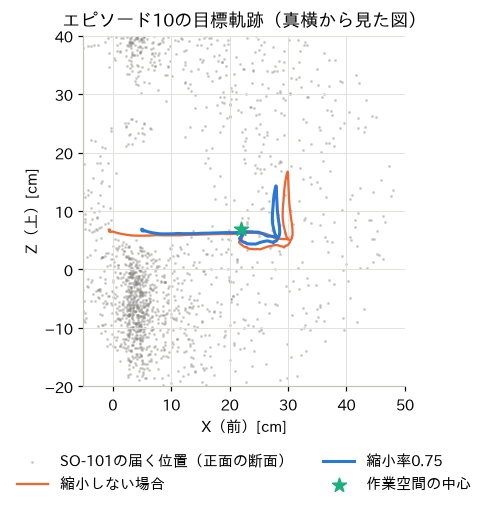

In [15]:
EXAMPLE_EP = 10 # 指定エピソード
actions, is_lost = get_episode(EXAMPLE_EP)

# 手順 ①〜④ だけを取り出して、縮小前後の軌跡を比べる
positions_robot = (R_CAM_TO_ROBOT @ accumulate_deltas(actions)[0][1:].T).T
centered = positions_robot - positions_robot.mean(axis=0)
targets_original = centered * 1.0 + WORKSPACE_CENTER          # 縮小しない場合
targets_scaled = centered * SCALE_FACTOR + WORKSPACE_CENTER   # 縮小率0.75

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(reach_slice[:, 0] * 100, reach_slice[:, 2] * 100, s=1,
           color=COLOR_MUTED, alpha=0.3, label="SO-101の届く位置（正面の断面）")
ax.plot(targets_original[:, 0] * 100, targets_original[:, 2] * 100,
        color=SERIES_COLORS[1], lw=1.5, label="縮小しない場合")
ax.plot(targets_scaled[:, 0] * 100, targets_scaled[:, 2] * 100,
        color=SERIES_COLORS[0], lw=2.0, label=f"縮小率{SCALE_FACTOR}")
ax.scatter(WORKSPACE_CENTER[0] * 100, WORKSPACE_CENTER[2] * 100, s=90,
           marker="*", color=SERIES_COLORS[2], zorder=3, label="作業空間の中心")
ax.set_xlim(-5, 50)
ax.set_ylim(-20, 40)
ax.set_aspect("equal")
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title(f"エピソード{EXAMPLE_EP}の目標軌跡（真横から見た図）")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.savefig(OUT_DIR / "03_scaled_trajectory.png", bbox_inches="tight")
plt.show()

縮小すると軌跡は作業空間の中心付近に集まるが、動作の始まりは縮小してもSO-101の根元の近くに残る。

02の成功地図で見たとおり、根元のすぐ前の低い位置はSO-101では届きにくく、失敗の可能性が高い。

## 2. グリッパー角の変換

### 2.1 なぜエピソードごとに正規化するのか

Grabetteのproximal角が「開いた状態」「閉じた状態」でそれぞれ何radになるかは、エピソードによって違う。
全エピソードについて、proximal角の最小値（最も開いた値）と最大値（最も閉じた値）を調べる。

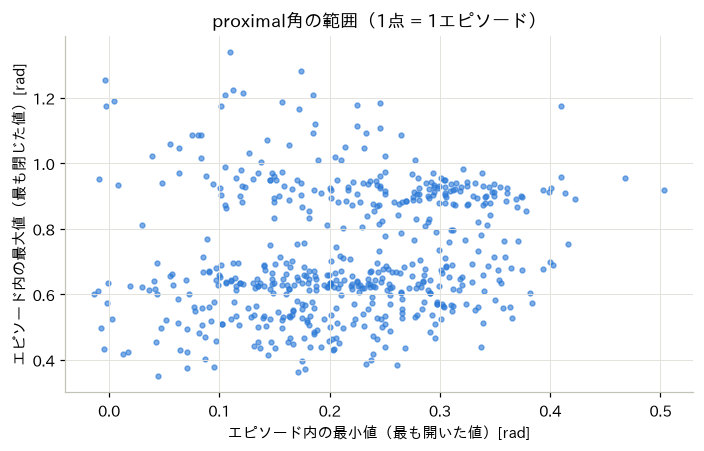

最小値の範囲: -0.01〜0.50 rad
最大値の範囲: 0.35〜1.34 rad


In [16]:
proximal_min = grabette_frames.groupby("episode_index")["action"].apply(
    lambda column: np.min([a[9] for a in column]))
proximal_max = grabette_frames.groupby("episode_index")["action"].apply(
    lambda column: np.max([a[9] for a in column]))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(proximal_min, proximal_max, s=10, color=SERIES_COLORS[0], alpha=0.6)
ax.set_xlabel("エピソード内の最小値（最も開いた値）[rad]")
ax.set_ylabel("エピソード内の最大値（最も閉じた値）[rad]")
ax.set_title("proximal角の範囲（1点 = 1エピソード）")
plt.tight_layout()
plt.savefig(OUT_DIR / "03_proximal_range.png", bbox_inches="tight")
plt.show()
print(f"最小値の範囲: {proximal_min.min():.2f}〜{proximal_min.max():.2f} rad")
print(f"最大値の範囲: {proximal_max.min():.2f}〜{proximal_max.max():.2f} rad")

最も開いた値も最も閉じた値も、エピソードによって大きく異なる。

各エピソードの最小値を全開、最大値を全閉*とみなし変換することとする。

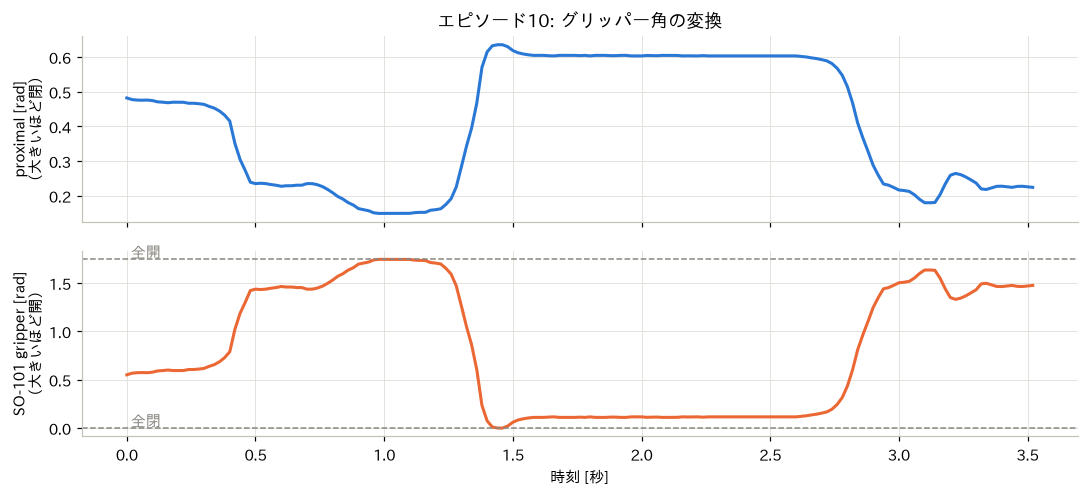

In [17]:
# エピソード10で、proximal角と変換後のSO-101グリッパー角を並べる
time_s = np.arange(len(actions)) / GRABETTE_FPS
gripper_so101 = proximal_to_so101(actions[:, 9], actions[:, 9].min(),
                                  actions[:, 9].max())

fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
axes[0].plot(time_s, actions[:, 9], color=SERIES_COLORS[0])
axes[0].set_ylabel("proximal [rad]\n（大きいほど閉）")
axes[0].set_title(f"エピソード{EXAMPLE_EP}: グリッパー角の変換")
axes[1].plot(time_s, gripper_so101, color=SERIES_COLORS[1])
axes[1].axhline(SO101_GRIPPER_OPEN, color=COLOR_MUTED, ls="--", lw=1)
axes[1].axhline(SO101_GRIPPER_CLOSED, color=COLOR_MUTED, ls="--", lw=1)
axes[1].text(0, SO101_GRIPPER_OPEN, " 全開", va="bottom", color=COLOR_MUTED)
axes[1].text(0, SO101_GRIPPER_CLOSED, " 全閉", va="bottom", color=COLOR_MUTED)
axes[1].set_ylabel("SO-101 gripper [rad]\n（大きいほど開）")
axes[1].set_xlabel("時刻 [秒]")
plt.tight_layout()
plt.savefig(OUT_DIR / "03_gripper_conversion.png", bbox_inches="tight")
plt.show()

proximalが最大（最も閉じる）の時刻にSO-101は全閉になり、最小の時刻に全開になる。

前段で用意したproximal_to_so101を用いることで、向きが逆になっていること、および全開から全閉まで使い切るように変換されていることが確認できる。

## 3. 1エピソードのリターゲット

ここまでの手順をretarget_episodeでまとめて実行する。

なお、平滑化の強さ（σ = 8フレーム）と1フレームあたりの関節角の変化の上限（8度）は、
IKが別の構えに飛び移ったときの急な動きを抑えるために設定した。

In [18]:
result = retarget_episode(actions, is_lost, kin)
valid = result["valid_mask"]
print(f"エピソード{EXAMPLE_EP}: {len(valid)}フレーム中{valid.sum()}フレームでIK成功 "
      f"（成功率{valid.mean():.1%}）")

エピソード10: 177フレーム中142フレームでIK成功 （成功率80.2%）


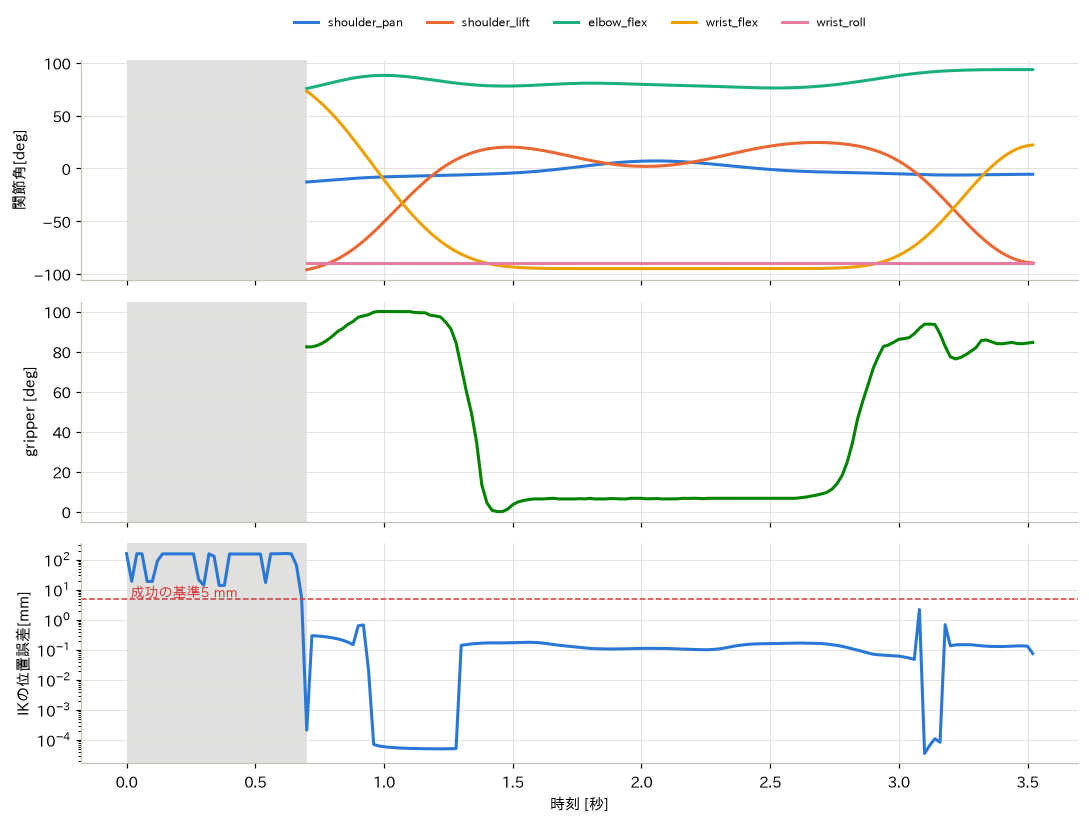

In [19]:
# 関節角の時系列（IK失敗フレームは灰色の帯）
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for j in range(6):
    # IK失敗フレームの関節角は使えない値なので、描かない（NaNにする）
    curve = np.where(valid, result["joint_angles"][:, j], np.nan)
    axes[0 if j < 5 else 1].plot(time_s, np.degrees(curve),
                                 color=SERIES_COLORS[j], label=JOINT_NAMES[j])
axes[0].set_ylabel("関節角[deg]")
axes[0].legend(ncol=5, fontsize=8, loc="upper center",
               bbox_to_anchor=(0.5, 1.25))
axes[1].set_ylabel("gripper [deg]")
axes[2].semilogy(time_s, np.where(np.isfinite(result["pos_errors"]),
                                  result["pos_errors"], np.nan) * 1000,
                 color=SERIES_COLORS[0])
axes[2].axhline(POS_TOL * 1000, color=COLOR_BAD, ls="--", lw=1)
axes[2].text(0, POS_TOL * 1000, " 成功の基準5 mm", color=COLOR_BAD,
             va="bottom", fontsize=9)
axes[2].set_ylabel("IKの位置誤差[mm]")
axes[2].set_xlabel("時刻 [秒]")
for ax in axes:
    for t in np.where(~valid)[0]:
        ax.axvspan(t / GRABETTE_FPS, (t + 1) / GRABETTE_FPS,
                   color=COLOR_MUTED, alpha=0.25, lw=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "03_example_joint_angles.png", bbox_inches="tight")
plt.show()

IKが失敗したフレーム（灰色の帯）では、位置誤差が5 mmを大きく超えているため、これらのフレームは学習データから除外する方針で進める。

## 4. 実データで起きるIKの失敗

02で、IKの失敗には「A. 届かない」「B. 初期値によって解けない」「C. 関節の可動範囲で止まる」があることを確認した。
実際のエピソードでは、それぞれどの程度起きているのか。
後で動画を確認する6エピソードで確認する。

`retarget_episode`は、各フレームの最終的な解が **どの初期値から得られたか** を`ik_source`に記録している。

| 記録値 | 意味 |
|---|---|
| warm | 前フレームの解から解いた（ウォームスタート） |
| init | 初期姿勢または予備姿勢から解き直した |
| neutral | 全関節0から解き直した |
| random | ランダムな姿勢から解き直した |
| lost | SLAMが位置を見失ったため解いていない |

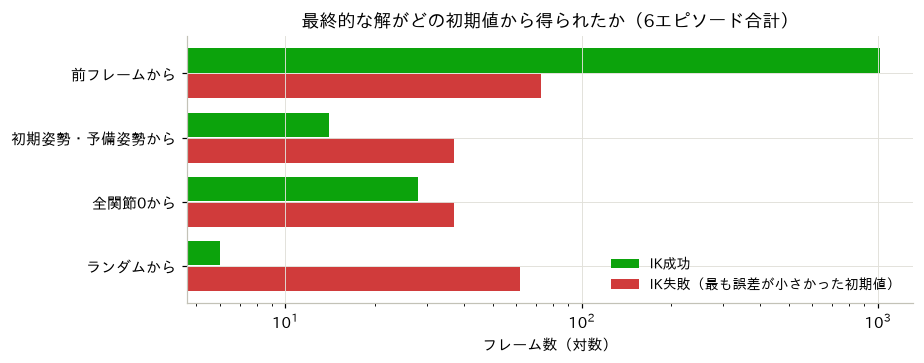

IK成功1064フレームのうち、初期値を変えた解き直しで成功したもの: 48（5%）


In [20]:
CHECK_EPISODES = [1, 2, 5, 6, 7, 10]
check_results = {}
for episode_id in CHECK_EPISODES:
    ep_actions, ep_lost = get_episode(episode_id)
    check_results[episode_id] = (ep_actions, ep_lost,
                                 retarget_episode(ep_actions, ep_lost, kin))

# 成功・失敗フレームそれぞれで、最終解の初期値の内訳を数える
sources = ["warm", "init", "neutral", "random"]
counts_ok = {s: 0 for s in sources}
counts_ng = {s: 0 for s in sources}
for _, _, res in check_results.values():
    for source, ok in zip(res["ik_source"], res["valid_mask"]):
        if source in sources:
            (counts_ok if ok else counts_ng)[source] += 1

labels = ["前フレームから", "初期姿勢・予備姿勢から", "全関節0から", "ランダムから"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(sources))
ax.barh(y - 0.2, [counts_ok[s] for s in sources], 0.38, color=COLOR_GOOD,
        label="IK成功")
ax.barh(y + 0.2, [counts_ng[s] for s in sources], 0.38, color=COLOR_BAD,
        label="IK失敗（最も誤差が小さかった初期値）")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("フレーム数（対数）")
ax.set_title("最終的な解がどの初期値から得られたか（6エピソード合計）")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "03_ik_source_breakdown.png", bbox_inches="tight")
plt.show()

n_ok = sum(counts_ok.values())
n_rescued = n_ok - counts_ok["warm"]
print(f"IK成功{n_ok}フレームのうち、初期値を変えた解き直しで成功したもの: "
      f"{n_rescued}（{n_rescued / n_ok:.0%}）")

ほとんどのフレームは前フレームの解から解けているが、成功したフレームの一部は、前フレームからは解けず、初期値を変えた解き直しで救われている。

02で単独の目標を解いたときには、初期値依存の失敗（種類B）は初期姿勢から遠い場所に限られていた。

### 4.1 例: 前フレームからは解けず、解き直して成功したフレーム（種類B）

実際に「前フレームの解から解くと失敗し、初期値を変えると成功した」フレームを1つ取り出し、2つの解を描画する。

該当フレーム数（6エピソード合計）: 46
例: エピソード6フレーム74（1.48秒）, 解き直しの初期値 = neutral
前フレームの解から: 失敗（誤差394.9 mm）
解き直した結果    : 成功（誤差0.5 mm）


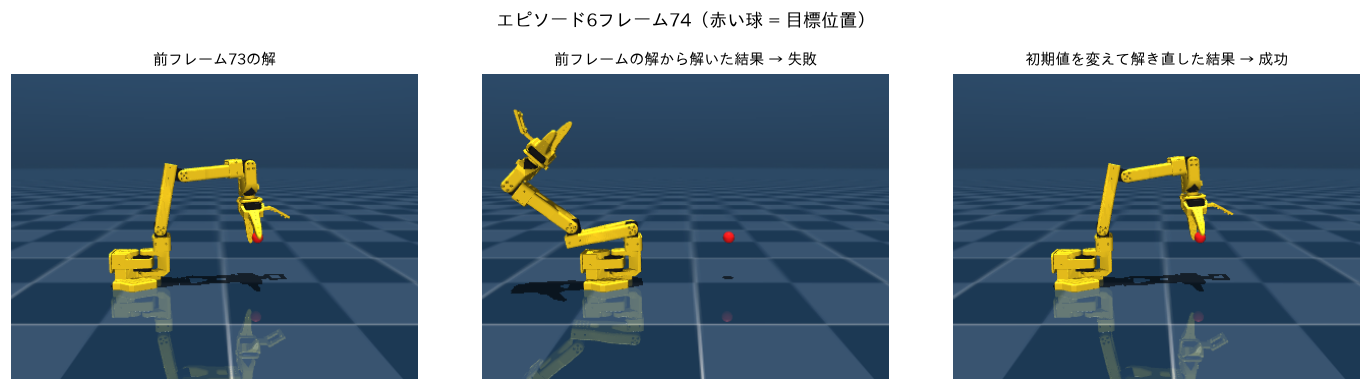

In [21]:
# 平滑化前のIKの解を得るため、後処理を無効にしてリターゲットし直す
# （後処理はIKループの後に行われるので、IKの解そのものは同じになる）
raw_results = {}
for episode_id in CHECK_EPISODES:
    ep_actions, ep_lost, _ = check_results[episode_id]
    raw_results[episode_id] = retarget_episode(ep_actions, ep_lost, kin,
                                               smooth_sigma=0, max_dq_deg=0)


def target_rotations(ep_actions):
    """目標の姿勢を作り直す（retarget_episodeの手順 ①〜③ と同じ計算）。"""
    rotations = np.einsum("ij,tjk->tik", R_CAM_TO_ROBOT,
                          accumulate_deltas(ep_actions)[1][1:])
    return np.einsum("tij,jk->tik", rotations, R_WRIST_FLIP)


def warm_start_attempt(raw, rotations, t):
    """
    フレームtを「直前の成功フレームの解」から解いた結果を再現する。

    retarget_episodeでは、成功した解だけが次フレームの初期値になる。
    そのため、tより前で最後に成功したフレームの解を初期値にする。
    """
    prev_valid = max(k for k in range(t) if raw["valid_mask"][k])
    q_prev = raw["joint_angles"][prev_valid].copy()
    target = pin.SE3(rotations[t], raw["ee_positions"][t])
    q_warm, ok_warm, err_warm = kin.ik(target, q_init=q_prev, pos_tol=POS_TOL)
    return prev_valid, q_prev, target, q_warm, ok_warm, err_warm


# 前フレームの解からは解けず、別の初期値で成功したフレームを6エピソードから集める
attempts = {}
for episode_id, raw_ep in raw_results.items():
    rotations = target_rotations(check_results[episode_id][0])
    for t in range(1, len(raw_ep["valid_mask"])):
        if (raw_ep["valid_mask"][t] and raw_ep["ik_source"][t] != "warm"
                and raw_ep["valid_mask"][:t].any()):
            attempts[(episode_id, t)] = warm_start_attempt(raw_ep,
                                                           rotations, t)
print(f"該当フレーム数（6エピソード合計）: {len(attempts)}")

# その中で、前フレームの解から解いたときの誤差が最も大きいものを例にする
ep_b, t_b = max(attempts, key=lambda key: attempts[key][5])
prev_valid, q_prev, target_b, q_warm, ok_warm, err_warm = attempts[(ep_b, t_b)]
raw_b = raw_results[ep_b]
print(f"例: エピソード{ep_b}フレーム{t_b}（{t_b / GRABETTE_FPS:.2f}秒）, "
      f"解き直しの初期値 = {raw_b['ik_source'][t_b]}")
print(f"前フレームの解から: {'成功' if ok_warm else '失敗'}（誤差{err_warm * 1000:.1f} mm）")
print(f"解き直した結果    : 成功（誤差{raw_b['pos_errors'][t_b] * 1000:.1f} mm）")

view = make_camera(azimuth=90, elevation=-10, distance=0.75,
                   lookat=(0.18, 0, 0.12))
pose_renderer = PoseRenderer(height=300, width=400)
marker = [(target_b.translation, (1.0, 0.1, 0.1, 0.9))]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, q, title in [
        (axes[0], q_prev, f"前フレーム{prev_valid}の解"),
        (axes[1], q_warm, "前フレームの解から解いた結果 → 失敗"),
        (axes[2], raw_b["joint_angles"][t_b],
         "初期値を変えて解き直した結果 → 成功")]:
    q_show = q.copy()
    q_show[4] = WRIST_ROLL_FIXED
    ax.imshow(pose_renderer.render(q_show, view, markers=marker))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle(f"エピソード{ep_b}フレーム{t_b}（赤い球 = 目標位置）", y=1.03)
plt.tight_layout()
plt.savefig(OUT_DIR / "03_ik_rescue_example.png", bbox_inches="tight")
plt.show()

### 4.2 例: どの初期値でも解けなかったフレーム（種類A）

次に、どの初期値からも5 mm以内に届かなかったフレームを取り出す。
その目標位置がSO-101の届く範囲のどこにあるかを確認する。

IK失敗フレーム数: 35  例: フレーム31（誤差162 mm）


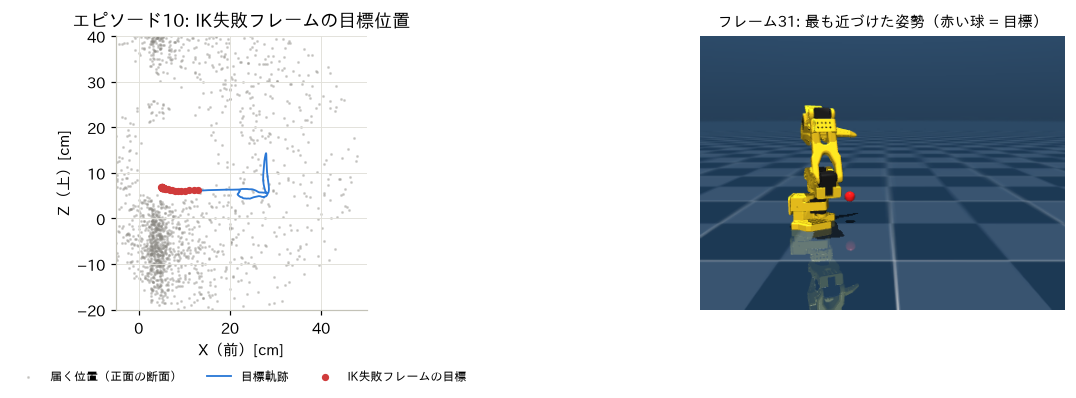

In [22]:
raw = raw_results[EXAMPLE_EP]      # エピソード10の、後処理前のIKの解
failed = np.where(~raw["valid_mask"] & ~is_lost)[0]
t_a = failed[np.argmax(raw["pos_errors"][failed])]        # 誤差が最大のフレーム
print(f"IK失敗フレーム数: {len(failed)}  例: フレーム{t_a}"
      f"（誤差{raw['pos_errors'][t_a] * 1000:.0f} mm）")

fig = plt.figure(figsize=(12, 3.8))
grid = fig.add_gridspec(1, 2, width_ratios=[1.1, 1])
ax = fig.add_subplot(grid[0])
ax.scatter(reach_slice[:, 0] * 100, reach_slice[:, 2] * 100, s=1,
           color=COLOR_MUTED, alpha=0.3, label="届く位置（正面の断面）")
ax.plot(raw["ee_positions"][:, 0] * 100, raw["ee_positions"][:, 2] * 100,
        color=SERIES_COLORS[0], lw=1.2, label="目標軌跡")
ax.scatter(raw["ee_positions"][failed, 0] * 100,
           raw["ee_positions"][failed, 2] * 100, s=14, color=COLOR_BAD,
           label="IK失敗フレームの目標", zorder=3)
ax.set_aspect("equal")
ax.set_xlim(-5, 50)
ax.set_ylim(-20, 40)
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title(f"エピソード{EXAMPLE_EP}: IK失敗フレームの目標位置")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
sub = fig.add_subplot(grid[1])
q_show = raw["joint_angles"][t_a].copy()
sub.imshow(pose_renderer.render(
    q_show, view, markers=[(raw["ee_positions"][t_a], (1, 0.1, 0.1, 0.9))]))
sub.set_title(f"フレーム{t_a}: 最も近づけた姿勢（赤い球 = 目標）", fontsize=10)
sub.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "03_ik_failure_example.png", bbox_inches="tight")
plt.show()

このエピソードでIKに失敗したフレームの目標（赤い点）は、ロボットの根元のすぐ前の低い位置にある。
02の成功地図で失敗（赤）だった領域であり、先端をここへ下ろすには腕を可動範囲を超えて折りたたむ必要があり、事実上不可能。

初期値をいくら変えても解けない失敗であり、学習データからは除外する。

### 5 FKによる最終確認

後処理で各関節の平準化をかけているため、先端はIKの目標から少しずれる。
最終的な関節角の先端位置をFKで計算し、目標とのずれを確かめる。

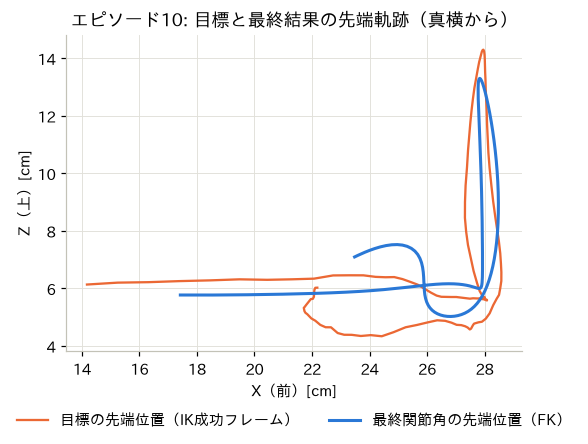

先端のずれ（6エピソード, IK成功フレーム）: 中央値9.2 mm, 95%のフレームで53.7 mm以下


In [23]:
final_tips = np.array([kin.fk(q).translation if ok else np.full(3, np.nan)
                       for q, ok in zip(result["joint_angles"], valid)])
deviation_mm = np.linalg.norm(final_tips - result["ee_positions"],
                              axis=1)[valid] * 1000

fig, ax = plt.subplots(figsize=(7.5, 4.2))
targets_valid = np.where(valid[:, None], result["ee_positions"], np.nan)
ax.plot(targets_valid[:, 0] * 100, targets_valid[:, 2] * 100,
        color=SERIES_COLORS[1], lw=1.5, label="目標の先端位置（IK成功フレーム）")
ax.plot(final_tips[:, 0] * 100, final_tips[:, 2] * 100,
        color=SERIES_COLORS[0], lw=2.0, label="最終関節角の先端位置（FK）")
ax.set_aspect("equal")
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title(f"エピソード{EXAMPLE_EP}: 目標と最終結果の先端軌跡（真横から）")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.savefig(OUT_DIR / "03_fk_final_check.png", bbox_inches="tight")
plt.show()

# 6エピソード全体でのずれ
all_dev = []
for _, _, res in check_results.values():
    for q, ok, target in zip(res["joint_angles"], res["valid_mask"],
                             res["ee_positions"]):
        if ok:
            all_dev.append(np.linalg.norm(kin.fk(q).translation - target))
all_dev = np.array(all_dev) * 1000
print(f"先端のずれ（6エピソード, IK成功フレーム）: 中央値{np.median(all_dev):.1f} mm, "
      f"95%のフレームで{np.percentile(all_dev, 95):.1f} mm以下")

最終結果の先端は、目標から中央値で1 cm程度ずれる。持ち上げの頂上や急な折り返しの所では数cmずれる。
（平滑化で細かな揺れや急な折り返しが丸められるため）。

一方で、前進・昇降といった基本動作の形は保たれていることから、本実施では滑らかさを優先し、このずれを許容する。

## 6. グラベット変換の目視確認（動画）

最後に、変換後の関節角でSO-101を動かした動画を、Grabetteの手元カメラ映像と左右に並べる。

- 左: Grabetteの手元カメラ映像（人の実演）
- 右: SO-101を真横から見た様子（変換結果）。IK失敗フレームは灰色、自己衝突フレームは赤みを付けて表示する

動画は50 fpsのデータを5フレームおきに描画し、10 fps（実時間と同じ速さ）で再生する。

In [24]:
import cv2

FRAME_STEP = 5          # 50 fpsのデータを5フレームおきに描画 → 10 fps


def put_label(image, lines, color=(255, 255, 255)):
    """画像の左上に英数字のラベルを書き込む（動画用）。"""
    image = image.copy()
    for k, line in enumerate(lines):
        cv2.putText(image, line, (8, 22 + 20 * k), cv2.FONT_HERSHEY_SIMPLEX,
                    0.55, color, 1, cv2.LINE_AA)
    return image


def make_comparison_frames(episode_id, ep_actions, res, pose_renderer):
    """Grabette映像とSO-101の描画を左右に並べたフレームの並びを作る。"""
    n_frames = len(ep_actions)
    frame_ids = list(range(0, n_frames, FRAME_STEP))
    human = grabette_video_frames(episode_id, frame_ids)
    camera = make_camera(distance=0.65)         # 真横から見るカメラ
    frames, collisions = [], []
    for k, t in enumerate(frame_ids):
        ok = bool(res["valid_mask"][t])
        if ok:
            robot = pose_renderer.render(res["joint_angles"][t], camera)
            collide = has_self_collision(res["joint_angles"][t])
        else:
            # IK失敗フレームは関節角が使えないため、灰色の画面にする
            robot = np.full((360, 480, 3), 60, dtype=np.uint8)
            collide = False
        if collide:
            robot = robot.astype(np.int32)
            robot[..., 0] = np.clip(robot[..., 0] + 90, 0, 255)
            robot[..., 1:] = robot[..., 1:] * 0.55
            robot = robot.astype(np.uint8)
        collisions.append(collide)
        status = "IK OK" if ok else "IK FAILED"
        if collide:
            status += "  SELF-COLLISION"
        grip = (f"gripper {np.degrees(res['joint_angles'][t, 5]):5.1f} deg"
                if ok else "")
        human_label = f"Grabette ep{episode_id}  t={t / GRABETTE_FPS:.1f}s"
        left = put_label(cv2.resize(human[k], (480, 360)), [human_label])
        right = put_label(robot, [f"SO-101 (retargeted)  {status}", grip])
        frames.append(np.concatenate([left, right], axis=1))
    return frames, frame_ids, collisions

In [25]:
video_dir = OUT_DIR / "03_videos"
summary_rows = []
pose_renderer_video = PoseRenderer(height=360, width=480)
for episode_id in CHECK_EPISODES:
    ep_actions, ep_lost, res = check_results[episode_id]
    frames, frame_ids, collisions = make_comparison_frames(
        episode_id, ep_actions, res, pose_renderer_video)
    path = save_mp4(frames, video_dir / f"ep{episode_id:03d}_comparison.mp4",
                    fps=10)
    valid_ids = [k for k, t in enumerate(frame_ids) if res["valid_mask"][t]]
    summary_rows.append({
        "エピソード": episode_id,
        "IK成功率": f"{res['valid_mask'].mean():.1%}",
        "自己衝突（描画フレーム中）": f"{np.mean([collisions[k] for k in valid_ids]):.0%}",
        "グリッパー最小角[deg]": round(float(np.degrees(
            res["joint_angles"][res["valid_mask"], 5].min())), 1),
        "動画": path.name,
    })
    ratio = res["valid_mask"].mean()
    show_mp4(path, width=900,
             title=f"エピソード{episode_id}（IK成功率{ratio:.1%}）")

In [26]:
# 6エピソードの結果一覧
summary = pd.DataFrame(summary_rows).set_index("エピソード")
summary.to_csv(OUT_DIR / "03_visual_check_summary.csv")
summary

,IK成功率,自己衝突（描画フレーム中）,グリッパー最小角[deg],動画
エピソード,,,,
1,88.6%,0%,43.4,ep001_comparison.mp4
2,79.6%,0%,0.0,ep002_comparison.mp4
5,86.8%,0%,0.0,ep005_comparison.mp4
6,83.9%,0%,0.0,ep006_comparison.mp4
7,76.2%,0%,0.0,ep007_comparison.mp4
10,80.2%,7%,0.0,ep010_comparison.mp4


### 7. 結論

動画とキーフレームで、人の動作とSO-101の動作を比べ、ある程度想定通りの挙動をしていると判断した。

- 人が物体へ手を伸ばす区間では、SO-101も腕を前に伸ばしている。
- 人が物体を持ち上げる区間では、SO-101も先端を持ち上げている。
- 人がグリッパーを閉じる時刻に、SO-101のグリッパー角も小さく（閉じる方向に）なっている。
- 変換後のSO-101の動作は、人の「近づく → 掴む → 持ち上げる → 戻す」と同じ意味の動作として理解できる。

IK失敗フレーム（灰色）は、基本的にエピソードの始まり（物体へ近づき始める前）にあり、十分に学習で使えると判断。

なお一部のエピソードではIK成功率が80%を下回る（エピソード2は79.6%、エピソード7は76.2%）。

このようなエピソードは欠けたフレームが多く、動作が途切れるため、のちの学習データ変換時点で除外する。